<a href="https://colab.research.google.com/github/akshat280706/ML-Lab-Experiment/blob/main/241080009_akshat_ML_LAB8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded=files.upload()

Saving heart_cleveland_upload.csv to heart_cleveland_upload.csv


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

In [ ]:
df=pd.read_csv("heart_cleveland_upload.csv")

df.columns=df.columns.str.strip().str.lower()
df=df.replace("?",np.nan)
for col in df.columns:
  df[col]=pd.to_numeric(df[col],errors="coerce")
df=df.dropna()
target="condition"
X=df.drop(columns=[target]).values.astype(float)
y=(df[target].values>0).astype(int)
print("shape:", df.shape)
print("without disease: ", np.sum(y==0))
print("with disease: ", np.sum(y==1))

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,
                                               random_state=42,stratify=y)
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)
y_svm=np.where(y_train==1,1,-1)
print("training: ",len(X_train))
print("testing: ",len(X_test))

shape: (297, 14)
without disease:  160
with disease:  137
training:  237
testing:  60



Library Linear SVM
Accuracy: 0.9
Precision: 1.0
Recall: 0.7857142857142857
F1-score: 0.88



my svm
Accuracy: 0.9
Precision: 1.0
Recall: 0.7857142857142857
F1-score: 0.88




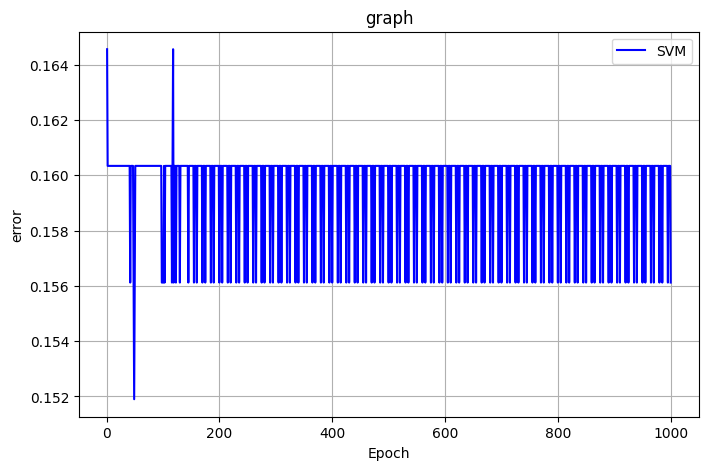


no of linear SV: 118

my kernel svm
Accuracy: 0.5333333333333333
Precision: 0.0
Recall: 0.0
F1-score: 0.0



lib svm
Accuracy: 0.8833333333333333
Precision: 0.92
Recall: 0.8214285714285714
F1-score: 0.8679245283018868



MLP Classifier
Accuracy: 0.9
Precision: 1.0
Recall: 0.7857142857142857
F1-score: 0.88




/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
def print_metrics(y_test, y_pred, model_name):
    print(f"\n{model_name}")
    print("Accuracy:",accuracy_score(y_test,y_pred))
    print("Precision:",precision_score(y_test,y_pred,zero_division=0))
    print("Recall:",recall_score(y_test,y_pred,zero_division=0))
    print("F1-score:",f1_score(y_test,y_pred,zero_division=0))
    print("\n")

#library linear svm baseline
sklearn_linear_svm=SVC(kernel="linear")
sklearn_linear_svm.fit(X_train,y_train)
y_pred_sklearn_linear=sklearn_linear_svm.predict(X_test)
print_metrics(y_test,y_pred_sklearn_linear,"Library Linear SVM")

#SVM(SGD)
#converting labels
Y1=np.where(y_train<=0,-1,1)
n_samples,n_features=X_train.shape
W=np.zeros(n_features)
B=0.0
alpha=0.001
c=5
epochs=1000
#stochastic grad descent
epoch_errors_linear = []
for epoch in range(epochs):
  for i in range(n_samples):
    #decision score
    score=np.dot(X_train[i],W)+B

    #margin condition
    if Y1[i]*score>=1:
      #satsisfied cond
      W=W-alpha*W
    else:
      #condt not satisfied
      W=W-alpha*(W-c*Y1[i]*X_train[i] b b )
      B=B-alpha*(-c*Y1[i])

  #error after epoch
  train_scores=np.dot(X_train,W)+B
  train_predictions=np.where(train_scores>0,1,0)
  error=np.mean(train_predictions!=y_train)
  epoch_errors_linear.append(error)

#test scores
y_predd=np.dot(X_test,W)+B
y_pred_linear=np.where(y_predd<=0,0,1)
print_metrics(y_test,y_pred_linear,"my svm")
#graph
plt.figure(figsize=(8, 5))
plt.plot(range(1,epochs+1),epoch_errors_linear,color="blue",label="SVM")
plt.xlabel("Epoch")
plt.ylabel("error")
plt.title("graph")
plt.grid(True)
plt.legend()
plt.show()

#support vector
final_scores=np.dot(X_train,W)+B
#training ex on or inside margin
support_vector_mask=Y1*final_scores<=1
custom_support_vector=X_train[support_vector_mask]
print("\nno of linear SV:",len(custom_support_vector))


#my my mykernal
gamma=0.1 #how quickly similarity decreases with dist
#random features
n_components=100
np.random.seed(42)

w_rff=np.random.normal(0,np.sqrt(2*gamma),(n_features,n_components))
b_rff=np.random.uniform(0,2*np.pi,n_components)

def transform_rff(data):
    return np.sqrt(2.0/n_components)*np.cos(np.dot(data,w_rff)+b_rff)
X_train_rff=transform_rff(X_train)
X_test_rff=transform_rff(X_test)

n_samples_rff,n_features_rff=X_train_rff.shape
W_rff_model=np.zeros(n_features_rff)
B_rff=0.0

for epoch in range(epochs):
    for i in range(n_samples_rff):
        score_rff=np.dot(X_train_rff[i],W_rff_model)+B_rff
        if Y1[i]*score_rff>=1:
            W_rff_model=W_rff_model-alpha*W_rff_model
        else:
            W_rff_model=W_rff_model-alpha*(W_rff_model-c*Y1[i]*X_train_rff[i])
            B_rff=B_rff-alpha*(-c*Y1[i])
y_predd_rff=np.dot(X_test_rff,W_rff_model)+B_rff
y_pred_custom_rff=np.where(y_predd_rff<=0,0,1)
print_metrics(y_test,y_pred_custom_rff,"my kernel svm")

#kernal lib
rbf_model=SVC(kernel="rbf",C=5,gamma="scale")
rbf_model.fit(X_train,y_train)
y_pred_sklearn_rbf=rbf_model.predict(X_test)
print_metrics(y_test,y_pred_sklearn_rbf,"lib svm")

#baseline
mlp_model=MLPClassifier(hidden_layer_sizes=(16,8),activation="relu",
                        max_iter=500,random_state=42)
mlp_model.fit(X_train,y_train)
y_pred_mlp=mlp_model.predict(X_test).flatten()
print_metrics(y_test,y_pred_mlp,"MLP Classifier")